# Week 9 · Build a weekly activity summary

**Python for a fitness app · 60-minute beginner workshop**

> **Today's app feature**
>
> Our fitness app needs one weekly view: the recorded run distance, the number of run days, progress toward a chosen distance goal, and a daily chart. We will assemble that feature from familiar Python pieces.

### By the end, you can

- Connect stored data, reusable calculations, decisions, and a chart.
- Trace which inputs produce each part of the summary.
- Change a recorded distance or goal and recompute the result.

### Our hour together

| Time | What we will do |
|---|---|
| 0–5 min | Meet the feature and recall what we need |
| 5–20 min | Learn through small examples |
| 20–35 min | Build the feature together |
| 35–45 min | Predict, change, and discuss |
| 45–55 min | Try two short exercises |
| 55–60 min | Compare results and ask questions |

### Getting started

This guided project revisits lists, functions, loops, conditionals, and plotting. Every definition and sample value is included below. Matplotlib must be available in the selected kernel, as in week 8. Keep the earlier notebooks nearby if you want a longer explanation of a concept.

All people and activity records in this notebook are fictional. Run code cells from top to bottom. Each notebook includes its own examples and starter definitions.


## 1. Describe what the runner should see

> **The feature · A weekly activity view**
>
> Sam wants to see how much running was recorded this week and how that total compares with a chosen distance goal. The chart should show which days contributed to the total.

| Part of the feature | Python we will use |
|---|---|
| Name, goal, day labels, and distances | Variables and lists |
| Total recorded distance | A function containing a loop |
| Number of days with a recorded run | A loop containing a condition |
| Progress message | A function containing a decision |
| Daily activity view | Matplotlib plotting calls |

We will build and inspect each part before displaying the complete summary. All distances are in kilometers. Zero means no run was recorded on that day.

## 2. Supply the week's inputs

Predict which day will have the tallest bar and whether the total will be below the chosen goal.


In [1]:
runner_name = "Sam"  # Store the name to display in the summary.
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]  # Store seven day labels in order.
daily_distances_km = [3.0, 0.0, 5.0, 2.0, 0.0, 4.0, 6.0]  # Store each day's recorded run distance.
weekly_goal_km = 18.0  # Store the fictional weekly distance goal chosen for this example.


## 3. Define a reusable total

> **Recall · Functions and accumulators**
>
> The parameter receives a list of distances. The accumulator starts at zero, the loop adds each distance, and `return` sends back the finished total. Keep `return` outside the loop so every item is included.


In [2]:
def weekly_distance(distances_km):  # Define a reusable total for a supplied list of distances.
    total_km = 0.0  # Start a fresh accumulator for this call.
    for distance_km in distances_km:  # Visit every supplied distance.
        total_km = total_km + distance_km  # Add this distance to the running total.
    return total_km  # Return the result after the loop finishes.


In [3]:
total_distance_km = weekly_distance(daily_distances_km)  # Calculate this week's total from the supplied list.
print("Recorded run distance:", total_distance_km, "km")  # Check the expected total of 20.0 km.


Recorded run distance: 20.0 km


## 4. Count the run days

Recall that `>` produces a Boolean value and an `if` body runs only when its condition is true. A zero-distance day does not increase this counter.


In [4]:
run_days = 0  # Start a fresh count of days with a recorded run.
for distance_km in daily_distances_km:  # Visit each of the seven daily values.
    if distance_km > 0:  # Check whether this day has a recorded run distance.
        run_days = run_days + 1  # Count this day when its distance is positive.
print("Days with a recorded run:", run_days)  # Check the expected count of five.


Days with a recorded run: 5


## 5. Choose a progress message

> **Recall · A decision can return text**
>
> A function's result can be a string. This function compares the total with a chosen goal and returns a message. `>=` treats both meeting and exceeding the goal as “goal reached.”


In [5]:
def distance_goal_message(total_km, goal_km):  # Define a message for a total and chosen distance goal.
    if total_km >= goal_km:  # Check whether the recorded distance reaches the goal.
        return "Weekly distance goal reached"  # Return the reached-goal message.
    else:  # Handle a total below the chosen goal.
        return "Below the chosen weekly distance goal"  # Return the below-goal message.


In [6]:
progress_message = distance_goal_message(total_distance_km, weekly_goal_km)  # Choose a message from the current total and goal.
print("Progress:", progress_message)  # Check that 20.0 km reaches the selected 18.0 km goal.


Progress: Weekly distance goal reached


## 6. Display the text summary

Each printed value now comes from a named input or calculation. `round(value, 2)` rounds the total for display. `len(days)` supplies the number of days covered by the record.


In [7]:
print("Weekly activity summary for", runner_name)  # Start the summary with the runner's name.
print("Days in this record:", len(days))  # Display the number of days represented.
print("Recorded run distance:", round(total_distance_km, 2), "km")  # Display the calculated distance with units.
print("Days with a recorded run:", run_days)  # Display the count from our loop.
print("Chosen weekly goal:", weekly_goal_km, "km")  # Display the goal used by our decision.
print("Progress:", progress_message)  # Display the message returned by our function.


Weekly activity summary for Sam
Days in this record: 7
Recorded run distance: 20.0 km
Days with a recorded run: 5
Chosen weekly goal: 18.0 km
Progress: Weekly distance goal reached


## 7. Add the daily chart

> **Recall · Import, plot, label, show**
>
> The import makes plotting functions available as `plt`. The day and distance lists match by position. Starting a fresh figure keeps this chart separate from earlier outputs.


In [8]:
import matplotlib.pyplot as plt  # Make Matplotlib's plotting functions available under the name plt.


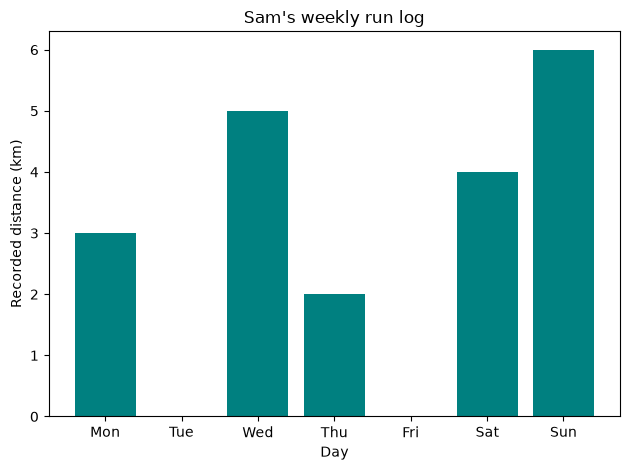

In [9]:
plt.figure()  # Start a new figure for the weekly activity view.
plt.bar(days, daily_distances_km, color="teal")  # Draw a bar for each day's recorded run distance.
plt.title(runner_name + "'s weekly run log")  # Join the runner's name with a descriptive chart title.
plt.xlabel("Day")  # Label the horizontal axis.
plt.ylabel("Recorded distance (km)")  # Label the vertical axis with units.
plt.ylim(bottom=0)  # Keep the distance bars anchored at zero.
plt.tight_layout()  # Adjust the layout so chart labels fit.
plt.show()  # Display the chart below the summary.


### Check the complete feature

With the supplied inputs, the summary should report **20.0 km**, **5 run days**, and a reached **18.0 km** goal. The tallest bar should be Sunday at **6.0 km**.

Discuss where each value came from. Which parts are stored input, and which parts were calculated?

## 8. Try a different goal

The goal can change without changing the recorded runs. Use the same total with a 25 km goal and predict the returned message.


In [10]:
alternative_goal_km = 25.0  # Choose another fictional goal for comparison.
alternative_message = distance_goal_message(total_distance_km, alternative_goal_km)  # Reuse the message function with the same total.
print("Alternative goal:", alternative_goal_km, "km")  # Display the goal used in this comparison.
print("Alternative progress:", alternative_message)  # Display the below-goal result for 20.0 km against 25.0 km.


Alternative goal: 25.0 km
Alternative progress: Below the chosen weekly distance goal


### Predict, change, and discuss

Edit Tuesday's distance in the **input cell** from 0.0 to 2.0 km, then run the notebook from the top. The total should become **22.0 km**, the run-day count should become **6**, and Tuesday should have a visible bar. Explain why all three results change.

> **Watch out · Keep derived results in sync**
>
> Changing an input does not automatically recalculate a stored total or redraw a chart. Rerun the downstream calculations after a change. Editing the input cell and running all cells is a reliable way to rebuild this feature.

### Key takeaways

- A small app feature can combine several simple, readable pieces.
- Functions give names to calculations and decisions we reuse.
- Checking known totals, messages, and chart values helps us verify the result.

You have now used Python to record activity, calculate results, organize data, make decisions, repeat work, save files, and draw charts. Keep these notebooks as examples to adapt when exploring another fitness app feature.


## Your turn · 10 minutes

> **Practice**
>
> Start with exercise 1. Try exercise 2 if time allows. Use the examples above, ask for help, and add a short inline comment to each Python line you write. The starter cells run as supplied; complete the tasks in the spaces marked with comments.


### Exercise 1 · Record a missed run

In the supplied independent week, Tuesday is at index `1`. Change its distance to **2.0 km**, then use `weekly_distance()` to calculate and print the updated total.

**Hint:** Assign to the list item before calling the function.

**Check:** The new weekly total should be **22.0 km**.


In [11]:
exercise_week_km = [3.0, 0.0, 5.0, 2.0, 0.0, 4.0, 6.0]  # Supply an independent week to edit.
# Update Tuesday's distance to 2.0 km.
# Calculate and display the new total with weekly_distance().


### Exercise 2 · Change a weekly goal

For a recorded total of **20.0 km**, use `distance_goal_message()` with goals of **18.0 km** and **25.0 km**. Display both returned messages.

**Hint:** Call the same function twice, keeping the total fixed and changing the second argument.

**Check:** The first message should say the goal was reached; the second should say the total is below the chosen goal.


In [12]:
exercise_total_km = 20.0  # Supply a total independently of the first exercise.
# Get and display the progress message for an 18.0 km goal.
# Get and display the progress message for a 25.0 km goal.
